# مشروع تحليل أرباح المبيعات

## 1. فهم المشكلة

يهدف هذا المشروع إلى تحليل بيانات المبيعات
والأرباح في متجر Superstore، لمعرفة أسباب
انخفاض الأرباح رغم ارتفاع حجم المبيعات.

## أهداف المشروع

- تحديد المنتجات الأكثر تحقيقًا للأرباح والخسائر.
- دراسة تأثير الخصومات على الأرباح.
- مقارنة أداء المبيعات بين المناطق المختلفة.
- اكتشاف أسباب الخسائر واقتراح حلول مناسبة.
- تصميم لوحة تحكم تفاعلية لعرض النتائج.

## سؤال العميل

لماذا تحقق بعض المنتجات مبيعات مرتفعة
ولكن أرباحها منخفضة أو تحقق خسائر؟

In [1]:
import pandas as pd

# قراءة بيانات المبيعات
df = pd.read_csv(
    "Sample - Superstore.csv",
    encoding="latin1"
)

# عرض حجم البيانات وأول خمسة صفوف
print("عدد الصفوف والأعمدة:", df.shape)
display(df.head())

عدد الصفوف والأعمدة: (9994, 21)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [2]:
# فحص جودة بيانات المبيعات

print("عدد الصفوف المكررة:", df.duplicated().sum())

print("\nالقيم المفقودة في كل عمود:")
print(df.isnull().sum())

print("\nملخص المبيعات والأرباح والخصومات:")
display(df[["Sales", "Profit", "Discount"]].describe())

عدد الصفوف المكررة: 0

القيم المفقودة في كل عمود:
Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64

ملخص المبيعات والأرباح والخصومات:


,Sales,Profit,Discount
count,9994.000000,9994.000000,9994.000000
mean,229.858001,28.656896,0.156203
std,623.245101,234.260108,0.206452
min,0.444000,-6599.978000,0.000000
25%,17.280000,1.728750,0.000000
50%,54.490000,8.666500,0.200000
75%,209.940000,29.364000,0.200000
max,22638.480000,8399.976000,0.800000


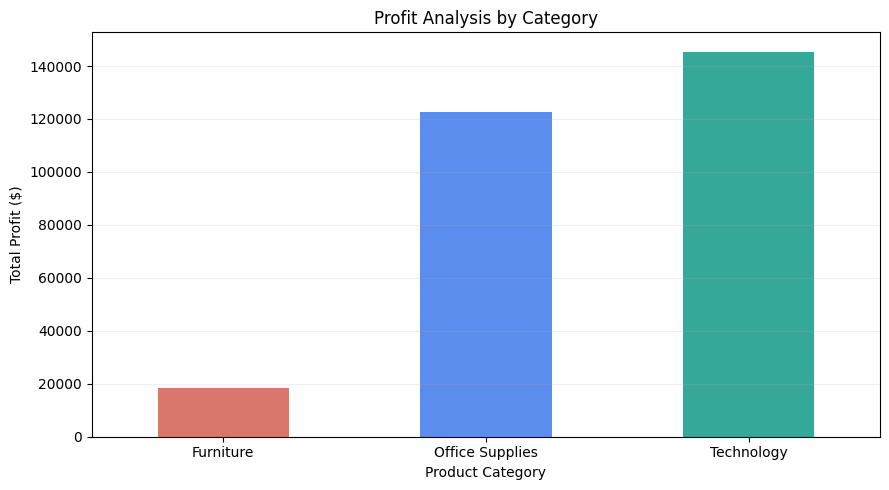

,Total Profit
Category,
Furniture,18451.2728
Office Supplies,122490.8008
Technology,145454.9481


In [3]:
import matplotlib.pyplot as plt

# حساب إجمالي الأرباح حسب فئة المنتج
category_profit = df.groupby("Category")["Profit"].sum()
category_profit = category_profit.sort_values()

# إنشاء الرسم البياني
plt.figure(figsize=(9, 5))

category_profit.plot(
    kind="bar",
    color=["#D9776A", "#5B8DEF", "#36A89A"]
)

plt.title("Profit Analysis by Category")
plt.xlabel("Product Category")
plt.ylabel("Total Profit ($)")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

# عرض النتائج بالأرقام
display(category_profit.to_frame("Total Profit"))

## 2. التحليل الاستكشافي للبيانات (EDA)

### الاكتشاف الأول: تفاوت الأرباح بين فئات المنتجات

بعد تحليل إجمالي الأرباح حسب فئات المنتجات،
لاحظت أن فئة التكنولوجيا حققت أعلى ربح
بقيمة 145,454.95 دولار، تليها المستلزمات
المكتبية بقيمة 122,490.80 دولار.

أما فئة الأثاث فقد حققت أقل إجمالي ربح
بقيمة 18,451.27 دولار.

### الاستنتاج
تشير النتائج إلى وجود تفاوت واضح في الأرباح
بين الفئات، مما يستدعي تحليل منتجات الأثاث
والخصومات المرتبطة بها لمعرفة أسباب
انخفاض ربحيتها.

### التوصية الأولية
مراجعة المنتجات الأقل ربحية ودراسة تأثير
الخصومات عليها قبل اتخاذ قرارات التسعير.

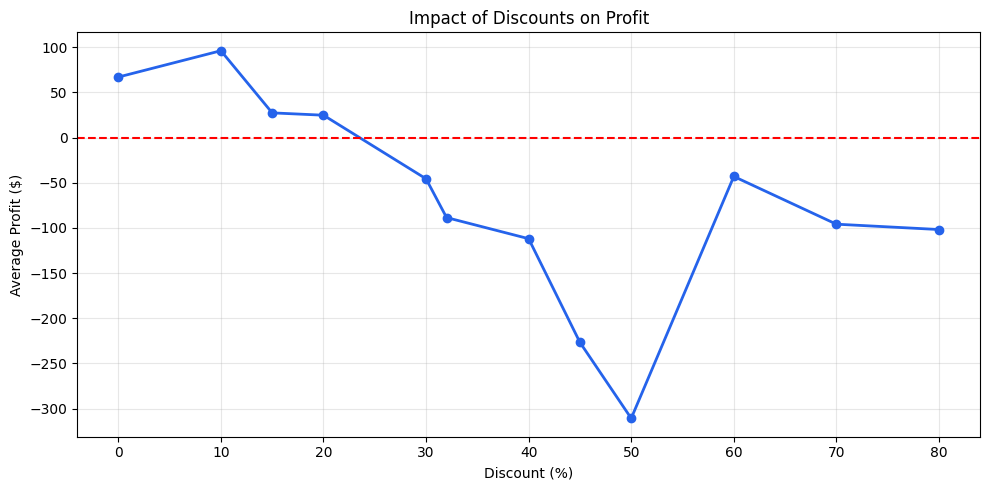

,Average Profit
Discount,
0.00,66.90
0.10,96.06
0.15,27.29
0.20,24.70
0.30,-45.68
0.32,-88.56
0.40,-111.93
0.45,-226.65
0.50,-310.70


In [4]:
# تحليل تأثير الخصومات على الأرباح

import matplotlib.pyplot as plt

discount_analysis = df.groupby("Discount")["Profit"].mean()

plt.figure(figsize=(10, 5))

plt.plot(
    discount_analysis.index * 100,
    discount_analysis.values,
    marker="o",
    color="#2563EB",
    linewidth=2
)

plt.axhline(0, color="red", linestyle="--")

plt.title("Impact of Discounts on Profit")
plt.xlabel("Discount (%)")
plt.ylabel("Average Profit ($)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# عرض النتائج بالأرقام
display(discount_analysis.round(2).to_frame("Average Profit"))

### الاكتشاف الثاني: تأثير الخصومات على الأرباح

بعد تحليل بيانات الخصومات، لاحظت وجود
علاقة بين ارتفاع نسب الخصم وانخفاض متوسط الأرباح.

عند خصم 20% كان متوسط الربح 24.70 دولار،
بينما انخفض إلى خسارة متوسطة قدرها
45.68 دولار عند خصم 30%.

كما وصلت الخسارة المتوسطة إلى 310.70 دولار
عند خصم 50%.

### الاستنتاج
تشير النتائج إلى أن الخصومات المرتفعة
ترتبط بانخفاض الربحية في بيانات المتجر،
وقد تكون أحد العوامل المساهمة في الخسائر.

### التوصية
مراجعة سياسة الخصومات، وخاصة الخصومات
التي تبدأ من 30%، ودراسة ربحية المنتجات
قبل تطبيق خصومات مرتفعة.

,Sales,Profit
Region,,
Central,501239.89,39706.36
East,678781.24,91522.78
South,391721.90,46749.43
West,725457.82,108418.45


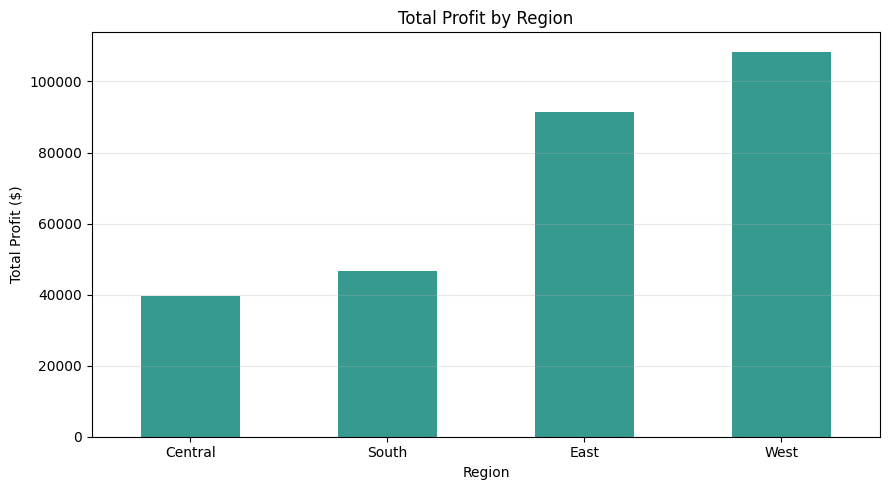

In [5]:
# تحليل المبيعات والأرباح حسب المنطقة

import matplotlib.pyplot as plt

region_analysis = df.groupby("Region")[["Sales", "Profit"]].sum()

# عرض النتائج
display(region_analysis.round(2))

# رسم إجمالي الأرباح حسب المنطقة
region_analysis["Profit"].sort_values().plot(
    kind="bar",
    figsize=(9, 5),
    color="#369A91"
)

plt.title("Total Profit by Region")
plt.xlabel("Region")
plt.ylabel("Total Profit ($)")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [6]:
# عرض أرباح المناطق مرتبة من الأقل إلى الأعلى
region_profit = (
    df.groupby("Region")["Profit"]
    .sum()
    .sort_values()
)

display(region_profit.round(2).to_frame("Total Profit ($)"))

,Total Profit ($)
Region,
Central,39706.36
South,46749.43
East,91522.78
West,108418.45


### الاكتشاف الثالث: اختلاف الأرباح بين المناطق

بعد تحليل إجمالي الأرباح حسب المناطق، لاحظت
وجود تفاوت واضح في الأداء.

حققت المنطقة الغربية أعلى إجمالي ربح بقيمة
108,418.45 دولار، تليها المنطقة الشرقية
بقيمة 91,522.78 دولار.

أما المنطقة الجنوبية فحققت 46,749.43 دولار،
بينما سجلت المنطقة الوسطى أقل إجمالي ربح
بقيمة 39,706.36 دولار.

### الاستنتاج
توضح النتائج أن أرباح المتجر تختلف بين المناطق،
وأن المنطقة الوسطى تحتاج إلى دراسة إضافية
لمعرفة أسباب انخفاض أرباحها مقارنة ببقية المناطق.

### التوصية
تحليل المبيعات والخصومات والمنتجات في
المنطقة الوسطى، ومقارنتها بالمناطق الأعلى
ربحية للوصول إلى فرص تحسين الأداء.

In [7]:
# اكتشاف العمليات التي حققت أكبر خسائر

losses = df[df["Profit"] < 0].copy()

print("عدد السجلات الخاسرة:", len(losses))

print("أكبر 5 عمليات خسارة:")
display(
    losses[
        ["Product Name", "Category", "Region",
         "Sales", "Discount", "Profit"]
    ].sort_values("Profit").head(5)
)

عدد السجلات الخاسرة: 1871
أكبر 5 عمليات خسارة:


,Product Name,Category,Region,Sales,Discount,Profit
7772,Cubify CubeX 3D Printer Double Head Print,Technology,East,4499.985,0.7,-6599.9780
683,Cubify CubeX 3D Printer Triple Head Print,Technology,South,7999.980,0.5,-3839.9904
9774,GBC DocuBind P400 Electric Binding System,Office Supplies,Central,2177.584,0.8,-3701.8928
3011,Lexmark MX611dhe Monochrome Laser Printer,Technology,West,2549.985,0.7,-3399.9800
4991,Ibico EPK-21 Electric Binding System,Office Supplies,Central,1889.990,0.8,-2929.4845


## 4. مفاجآت البيانات

### المفاجأة الأولى: وجود عدد كبير من السجلات الخاسرة

أثناء تحليل البيانات، اكتشفت وجود 1,871 سجلًا
حقق أرباحًا سالبة من أصل 9,994 سجلًا.

- العمود: Profit
- طريقة الاكتشاف: البحث عن القيم الأقل من الصفر.
- القرار المبدئي: الاحتفاظ بهذه السجلات وتحليلها،
لأنها تمثل المشكلة الأساسية للمشروع.

### المفاجأة الثانية: خسارة مرتفعة في أحد المنتجات

لاحظت أن إحدى عمليات بيع طابعة
Cubify CubeX 3D Printer
سجلت خسارة قدرها 6,599.98 دولار،
مع خصم بنسبة 70%.

- الأعمدة: Product Name وProfit وDiscount
- طريقة الاكتشاف: ترتيب السجلات حسب أكبر خسارة.
- القرار المبدئي: مراجعة الخصومات المرتفعة
والمنتجات التي تحقق خسائر كبيرة.

### المفاجأة الثالثة: الخصومات المرتفعة

لاحظت أن أكبر خمس عمليات خسارة ارتبطت
بخصومات تتراوح بين 50% و80%.

- الأعمدة: Discount وProfit
- طريقة الاكتشاف: مقارنة نسب الخصم بالخسائر.
- القرار المبدئي: دراسة العلاقة بين الخصومات
والربحية قبل اقتراح تعديل سياسة التسعير.

### الخلاصة

سأحتفظ بالسجلات الخاسرة خلال مرحلة التحليل،
لأن حذفها قد يؤدي إلى إخفاء المشكلة الفعلية.
وسأستخدم النتائج لاحقًا في تصميم لوحة تحكم
تساعد على متابعة الأرباح والخسائر.